# Capstone – Fake news detector
## Notebook 3 – Comparison: sentence embeddings vs TF-IDF

**Goal:** the brief asks for at least one evaluation comparing two approaches. We compare the baseline of notebook 2 with a second representation seen in Lab 3.2:

| | Approach A – baseline (notebook 2) | Approach B – this notebook |
|---|---|---|
| Representation | TF-IDF on words and bigrams | **sentence embeddings** from `all-MiniLM-L6-v2` (BERT-based model of Lab 3.2) |
| Text given to the model | title + full text, cleaned, lemmatized | title + beginning of the text, cleaned, **not** lemmatized (the transformer needs natural sentences) |
| Classifier | logistic regression | logistic regression |

Both are trained on the same train set and evaluated on the **same test set**.

Vocabulary:
- **Sentence embedding:** a vector of 384 numbers that represents the *meaning* of a whole text. Texts with similar meaning get close vectors, even if they use different words.
- **BERT** (Bidirectional Encoder Representations from Transformers): the transformer family the embedding model comes from.
- **t-SNE** (t-distributed Stochastic Neighbor Embedding): projects high-dimensional vectors in 2-D to visualise them (Lab 3.2, Part D).

Question we want to answer: does a representation of the **meaning** do better than a representation of the **words** – and is it less dependent on the writing style of each source?

## Setup

In [1]:
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

sys.path.append("..")
from src.preprocessing import build_input, remove_leaks

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 150)
RANDOM_STATE = 42
LABELS = {0: "fake", 1: "real"}
DATA_DIR = Path("../data")
MODEL_DIR = Path("../models")

# Part 1 – Load the data (same cleaning as notebook 2)

In [2]:
frames = []
for split_name in ["train", "validation", "test"]:
    part = pd.read_parquet(DATA_DIR / f"{split_name}-00000-of-00001.parquet")
    part["split"] = split_name
    frames.append(part)
df = pd.concat(frames, ignore_index=True).drop(columns=["Unnamed: 0"], errors="ignore")
df["title"] = df["title"].fillna("")
df["text"] = df["text"].fillna("")
df = df[df["text"].str.strip() != ""]
df = df.drop_duplicates(subset="text").reset_index(drop=True)

train, val, test = (df[df["split"] == s].reset_index(drop=True) for s in ["train", "validation", "test"])
y_train, y_val, y_test = train["label"].to_numpy(), val["label"].to_numpy(), test["label"].to_numpy()
print(f"train {len(train)}, validation {len(val)}, test {len(test)}")

train 24352, validation 8116, test 8117


# Part 2 – Text given to the embedding model

- **Same leak removal** as notebook 2 (`remove_leaks`): no *Reuters*, image credits, URLs, tweet links, handles, video tags. Otherwise the comparison would not be fair.
- **No lowercasing, no stop word removal, no lemmatization:** the transformer was trained on normal sentences; it uses the grammar and the small words to understand the meaning.
- **Only the beginning of the article:** `all-MiniLM-L6-v2` reads at most 256 tokens (word pieces, about 180-200 words) and ignores the rest. We keep the title + the first 200 words of the text.

In [3]:
MAX_WORDS = 200

def embedding_input(title, text, max_words=MAX_WORDS):
    title, text = remove_leaks(title), remove_leaks(text)
    words = " ".join(text.split()[:max_words])
    return f"{' '.join(title.split())}. {words}"

for s in (train, val, test):
    s["input_emb"] = [embedding_input(t, x) for t, x in zip(s["title"], s["text"])]

print(test["input_emb"].iloc[0][:300])

FORMER U.S. ATTORNEY: “It’s VERY Clear Intel Conspired to Frame Trump”. JOE DIGENOVA has been around D.C for decades and has seen it all. He probably didn t see his one coming. The incoming president was set-up to be taken down. A soft coup is in the works and DiGenova has this to say about it:"It's


# Part 3 – Compute the embeddings

Encoding ~40k articles takes time on a laptop (about 10-20 minutes the first time, faster with an Apple Silicon GPU, which `sentence-transformers` uses automatically if available). The vectors are **saved in `data/`** (not pushed to GitHub): the next runs load them in a few seconds.

In [4]:
EMB_MODEL_NAME = "all-MiniLM-L6-v2"
encoder = SentenceTransformer(EMB_MODEL_NAME)
print("Device:", encoder.device, "– max tokens:", encoder.max_seq_length)

def get_embeddings(split_df, split_name):
    path = DATA_DIR / f"embeddings_{EMB_MODEL_NAME}_{split_name}_{MAX_WORDS}w.npy"
    if path.exists():
        emb = np.load(path)
        if len(emb) == len(split_df):
            print(f"{split_name}: loaded from {path.name}")
            return emb
    start = time.time()
    emb = encoder.encode(split_df["input_emb"].tolist(), batch_size=64, show_progress_bar=True,
                         normalize_embeddings=True)
    np.save(path, emb)
    print(f"{split_name}: encoded in {time.time() - start:.0f} s, saved to {path.name}")
    return emb

X_train = get_embeddings(train, "train")
X_val = get_embeddings(val, "validation")
X_test = get_embeddings(test, "test")
print(X_train.shape)

Device: mps:0 – max tokens: 256
train: loaded from embeddings_all-MiniLM-L6-v2_train_200w.npy
validation: loaded from embeddings_all-MiniLM-L6-v2_validation_200w.npy
test: loaded from embeddings_all-MiniLM-L6-v2_test_200w.npy
(24352, 384)


# Part 4 – Logistic regression on the embeddings

We try a few values of `C` (the inverse of the regularisation strength: small `C` = simpler model) and keep the best one on the **validation** set.

In [5]:
tuning = {}
for C in [0.1, 1, 10, 100]:
    clf = LogisticRegression(C=C, max_iter=2000)
    clf.fit(X_train, y_train)
    pred = clf.predict(X_val)
    tuning[C] = {"accuracy": accuracy_score(y_val, pred), "F1 macro": f1_score(y_val, pred, average="macro")}
tuning = pd.DataFrame(tuning).T.rename_axis("C")
display(tuning.round(4))

best_C = tuning["F1 macro"].idxmax()
emb_clf = LogisticRegression(C=best_C, max_iter=2000).fit(X_train, y_train)
print("Best C:", best_C)

,accuracy,F1 macro
C,,
0.1,0.8940,0.8931
1.0,0.9209,0.9203
10.0,0.9292,0.9286
100.0,0.9299,0.9294


Best C: 100.0


**Interpretation:** the score improves as `C` grows (89.4% at C = 0.1 → 93.0% at C = 100): with only 384 dimensions, the model needs little regularisation. We keep **C = 100** (validation accuracy 93.0%).

# Part 5 – Head-to-head on the test set

The baseline is the model saved by notebook 2 (`models/baseline_tfidf_logreg.joblib`). If the file is missing, run notebook 2 first.

In [6]:
baseline = joblib.load(MODEL_DIR / "baseline_tfidf_logreg.joblib")
test["input_tfidf"] = [build_input(t, x) for t, x in zip(test["title"], test["text"])]

predictions = {
    "A – TF-IDF + logistic regression": baseline.predict(test["input_tfidf"]),
    "B – embeddings + logistic regression": emb_clf.predict(X_test),
}

def time_per_article(fn, n=500):
    start = time.time()
    fn(n)
    return (time.time() - start) / n * 1000

speed = {
    "A – TF-IDF + logistic regression": time_per_article(
        lambda n: baseline.predict([build_input(t, x) for t, x in zip(test["title"][:n], test["text"][:n])])),
    "B – embeddings + logistic regression": time_per_article(
        lambda n: emb_clf.predict(encoder.encode(test["input_emb"][:n].tolist(), batch_size=64))),
}

comparison = pd.DataFrame({
    name: {
        "accuracy": accuracy_score(y_test, pred),
        "F1 macro": f1_score(y_test, pred, average="macro"),
        "F1 fake": f1_score(y_test, pred, pos_label=0),
        "F1 real": f1_score(y_test, pred, pos_label=1),
        "errors": int((pred != y_test).sum()),
        "ms per article": speed[name],
    }
    for name, pred in predictions.items()
}).T
comparison.round(4)

,accuracy,F1 macro,F1 fake,F1 real,errors,ms per article
A – TF-IDF + logistic regression,0.9654,0.9652,0.9629,0.9675,281.0,1.4233
B – embeddings + logistic regression,0.9272,0.9268,0.9214,0.9322,591.0,3.6889


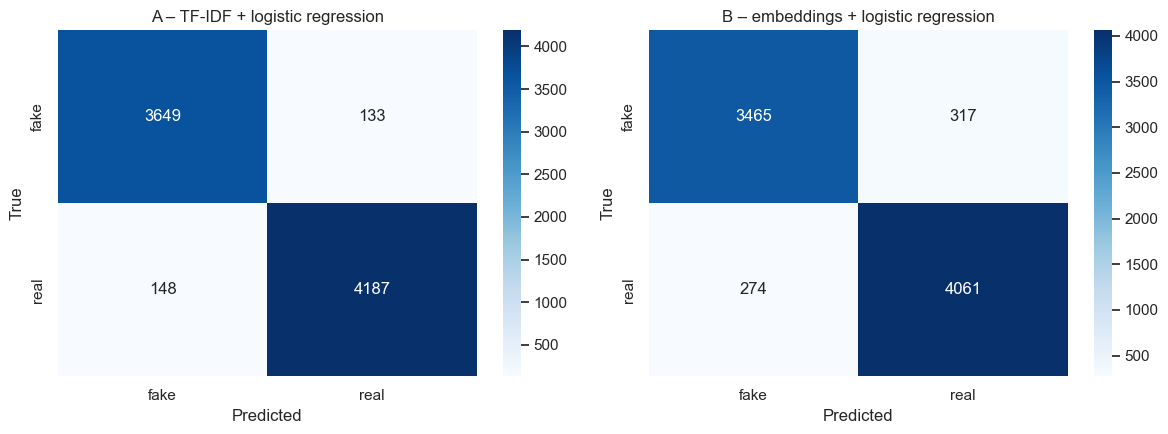

A – TF-IDF + logistic regression
              precision    recall  f1-score   support

        fake     0.9610    0.9648    0.9629      3782
        real     0.9692    0.9659    0.9675      4335

    accuracy                         0.9654      8117
   macro avg     0.9651    0.9653    0.9652      8117
weighted avg     0.9654    0.9654    0.9654      8117

B – embeddings + logistic regression
              precision    recall  f1-score   support

        fake     0.9267    0.9162    0.9214      3782
        real     0.9276    0.9368    0.9322      4335

    accuracy                         0.9272      8117
   macro avg     0.9272    0.9265    0.9268      8117
weighted avg     0.9272    0.9272    0.9272      8117



In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["fake", "real"], yticklabels=["fake", "real"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

for name, pred in predictions.items():
    print(name)
    print(classification_report(y_test, pred, target_names=["fake", "real"], digits=4))

**Interpretation:** on the same 8,117 test articles, **TF-IDF wins clearly**: 96.5% accuracy vs 92.7% for the embeddings – roughly **half as many errors** (281 vs 591). The embedding model is weaker on both classes (F1 fake 92.1%, F1 real 93.2%). Both are fast enough for an app (a few milliseconds per article).

# Part 6 – Where do the two approaches differ?

1. Error rate by sub-group (the "real – other source" group of notebook 2 is probably label noise).
2. Agreement: on how many articles do both models give the same answer, and who is right when they disagree?

In [8]:
group = np.where(test["label"] == 0, "fake",
                 np.where(test["text"].str.contains(r"\(Reuters\)"), "real – Reuters", "real – other source"))
by_group = pd.DataFrame({name: pd.Series(pred != y_test).groupby(group).mean()
                         for name, pred in predictions.items()})
by_group.insert(0, "articles", pd.Series(group).value_counts())
by_group.round(4)

,articles,A – TF-IDF + logistic regression,B – embeddings + logistic regression
fake,3782,0.0352,0.0838
real – Reuters,4149,0.0082,0.0364
real – other source,186,0.6129,0.6613


**Interpretation:** the embeddings make more errors in **every** group: about 2.5× more on fake articles (8.4% vs 3.6%) and almost 5× more on Reuters articles (3.6% vs 0.8%). On the "real – other source" group (probable label noise) both fail on about two thirds of the articles – both models say these texts look like fake news.

In [9]:
pred_a, pred_b = predictions.values()
agree = pred_a == pred_b
print(f"Both models give the same answer on {agree.mean():.2%} of the test articles")
print(f"Both wrong                   : {((pred_a != y_test) & (pred_b != y_test)).sum()}")
print(f"Only A (TF-IDF) right        : {((pred_a == y_test) & (pred_b != y_test)).sum()}")
print(f"Only B (embeddings) right    : {((pred_a != y_test) & (pred_b == y_test)).sum()}")

disagree = test[~agree].assign(true=lambda d: d["label"].map(LABELS),
                               tfidf=pred_a[~agree], embeddings=pred_b[~agree])
disagree["tfidf"] = disagree["tfidf"].map(LABELS)
disagree["embeddings"] = disagree["embeddings"].map(LABELS)
disagree["text_start"] = disagree["text"].str[:120]
disagree[["title", "text_start", "true", "tfidf", "embeddings"]].sample(min(10, len(disagree)), random_state=RANDOM_STATE)

Both models give the same answer on 93.67% of the test articles
Both wrong                   : 179
Only A (TF-IDF) right        : 412
Only B (embeddings) right    : 102


,title,text_start,true,tfidf,embeddings
4721,document préparatoire de la présidence russe,he lied period,fake,fake,real
7874,WATCH KELLYANNE CONWAY’S MIC DROP: “I think the biggest fake news was that Donald Trump couldn’t win.”,Kellyanne Conway: I think the biggest fake news was that Donald Trump couldn t win. pic.twitter.com/T5i68K0gW4 Washi,fake,fake,real
6905,SEC OF STATE REX TILLERSON: “Steps Are Under Way” To Remove Syria’s Bashar al-Assad…“Russian Government” Should “Consider Carefully Continued Supp...,The world is going to need to make some major adjustments now that the apologists have left the White House Sec of State,fake,real,fake
2695,Death toll in attack on mosque in Egypt's north Sinai rises to 184: state television,"CAIRO (Reuters) - The death toll in a militant attack on mosque in Egypt s north Sinai region has risen to 184 killed, E",real,real,fake
7886,"Trump, Macron engage in a little handshake diplomacy",BRUSSELS (Reuters) - U.S. President Donald Trump and French President Emmanuel Macron barely know each other but they se,real,fake,real
2104,"Factbox: Trump on Twitter - Media, American troops, Stock market","The following statements were posted to the verified Twitter accounts of U.S. President Donald Trump, @realDonaldTrump a",real,real,fake
3438,Trump Gets SKEWERED For Trying To Take Credit For Investment Ford Planned In 2015,Donald Trump continues to embarrass himself in a desperate effort to prove that he s a job creator.In yet another self-s,fake,fake,real
8066,White House: no sign of collusion in campaign aides' indictments,WASHINGTON (Reuters) - The indictments of two former Trump campaign aides on Monday have nothing to do with President Do,real,real,fake
5053,Obama's Cuba meetings will not be negotiated with Cuban government: White House,"WASHINGTON (Reuters) - The list of people, including dissidents, President Barack Obama plans to invite to meet with him",real,real,fake
3929,Paul Ryan Wants To Make This Healthcare Nightmare A Reality Again (VIDEO),"On Wednesday, Republican House Speaker Paul Ryan called for an end to protections found in the Affordable Care Act that",fake,real,fake


**Interpretation:** the two models agree on 93.7% of the articles. When they disagree, TF-IDF is right about four times more often than the embeddings (412 vs 102 articles). Many disagreements are fake articles with a sensational title but a factual body, or short Reuters pieces: the embedding model only reads the beginning of the article and represents its *topic*, which both classes share.

# Part 7 – Visualising the embeddings with t-SNE

Each point is an article of the test set, projected from 384 dimensions to 2 (Lab 3.2, Part D). If fake and real articles form separate regions, the embedding captures a difference between the two classes.

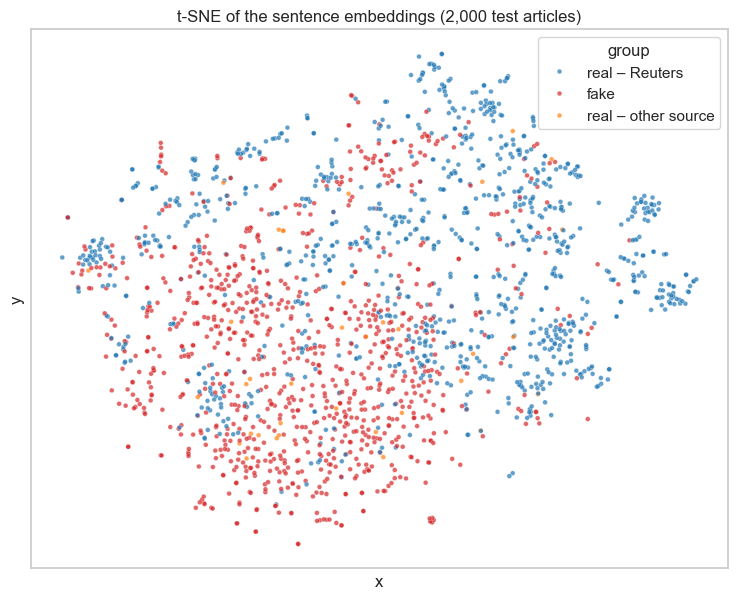

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(test), size=min(2000, len(test)), replace=False)
points = TSNE(n_components=2, random_state=RANDOM_STATE, init="pca", perplexity=30).fit_transform(X_test[idx])

plot_df = pd.DataFrame({"x": points[:, 0], "y": points[:, 1], "group": group[idx]})
plt.figure(figsize=(9, 7))
sns.scatterplot(data=plot_df, x="x", y="y", hue="group", s=12, alpha=0.7,
                palette={"fake": "tab:red", "real – Reuters": "tab:blue", "real – other source": "tab:orange"})
plt.title("t-SNE of the sentence embeddings (2,000 test articles)")
plt.xticks([])
plt.yticks([])
plt.show()

**Interpretation:** fake articles (red) are concentrated in the lower-left part of the map and Reuters articles (blue) in the upper-right part, with small tight blue clusters (probably specific world-news topics, e.g. one country or event). But there is a **large overlap in the middle**: many fake and real articles talk about the same subjects (Trump, Clinton, elections). The "real – other source" articles (orange) fall **inside the fake region** – one more sign that they are mislabelled.

# Part 8 – Save the embedding classifier

The app can offer both models. The embedding model itself (`all-MiniLM-L6-v2`) is downloaded by `sentence-transformers`; we only save the logistic regression trained on top of it.

In [11]:
path = MODEL_DIR / "embeddings_logreg.joblib"
joblib.dump({"classifier": emb_clf, "encoder_name": EMB_MODEL_NAME, "max_words": MAX_WORDS}, path)
print(f"Saved: {path} ({path.stat().st_size / 1e3:.0f} kB)")

Saved: ../models/embeddings_logreg.joblib (4 kB)


# Summary

1. **Approach B:** sentence embeddings of `all-MiniLM-L6-v2` (Lab 3.2) computed on the title + first 200 words, same leak removal as notebook 2, then logistic regression (best C = 100 on validation). Encoding the 40k articles took about 80 seconds on the Mac GPU.
2. **Result on the same test set:** **TF-IDF + logistic regression 96.5% accuracy vs 92.7% for embeddings + logistic regression** (F1 macro 96.5% vs 92.7%). The baseline makes about half as many errors (281 vs 591).
3. **By group:** the embeddings are worse everywhere (fake: 8.4% errors vs 3.6%; Reuters: 3.6% vs 0.8%). Both fail on the "real – other source" articles (about 2 in 3 wrong), which confirms the label noise found in notebook 2.
4. **Agreement:** the models give the same answer on 93.7% of the articles; when they disagree, TF-IDF is right about four times more often.
5. **Why TF-IDF wins here:**
   - The task is mostly about **style** (agency vs blog, notebook 2): specific words (*said*, days of the week, *via*, *watch*) are exactly what TF-IDF captures, while a sentence embedding is designed to capture the **topic / meaning**, which both classes share (US politics).
   - The embedding model only reads the first ~200 words; TF-IDF uses the whole article.
   - `all-MiniLM-L6-v2` is a small general-purpose model, not trained for fake news; we only train a logistic regression on top of it (no fine-tuning).
6. **t-SNE:** fake and real articles occupy different regions but overlap a lot in the middle; the "other source" articles fall in the fake region.
7. **Decision for the app:** the **TF-IDF + logistic regression** model is the main model (better score, explainable words, no download needed). The embedding model is kept as a comparison: being less dependent on exact words, it may resist better on recent articles from other sources – this is tested in notebook 4.
8. **Limits:** one embedding model only, no fine-tuning; comparison on test articles of the same sources and period as the training data.